In [ ]:
!pip install -q pandas matplotlib openpyxl numpy

cell 2

In [ ]:
import os
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import LogLocator, MultipleLocator, NullFormatter

# ---- matplotlib publication styling ----------------------------------------
plt.rcParams.update({
    "font.family":      "serif",
    "font.serif":       ["DejaVu Serif", "Times New Roman", "Times"],
    "font.size":        12,
    "axes.linewidth":   1.1,
    "mathtext.fontset": "dejavuserif",
    "savefig.dpi":      300,
})

# ---- energy window for comparison -------------------------------------------
E_MIN, E_MAX = 1.0, 20.0          # MeV — range where ALL sources are present

# ---- expected file names ----------------------------------------------------
FILES = {
    "EXFOR": "Fe-57_n_p_Mn-57 exfor.csv",
    "TENDL": "Fe57 tendl.csv",
    "ENDF":  "Fe 57 ( n,p ) endf raw data jendl  .txt",
    "JEFF":  "JEFF_Fe57_np_CrossSection_1MeV_to_40MeV.csv",
    "TALYS": "TALYS DATA for Fe 57.xlsx",
}

# ---- unit conversions -------------------------------------------------------
B_TO_MB  = 1000.0    # barns  -> millibarns
EV_TO_MEV = 1e-6     # eV     -> MeV


def _norm(s):
    """Lowercase + strip spaces/underscores/hyphens for fuzzy matching."""
    return s.lower().replace(" ", "").replace("_", "").replace("-", "")


def resolve(key):
    """Find file in data/ directory matching the given source key."""
    DATA_DIR = "data"
    sigs = {"EXFOR": "exfor", "TENDL": "tendl", "ENDF": "endf",
            "JEFF": "jeff", "TALYS": "talys"}
    want = sigs[key]
    for fn in os.listdir(DATA_DIR):
        n = _norm(fn)
        if want in n or (key == "ENDF" and "jendl" in n):
            return os.path.join(DATA_DIR, fn)
    return None

cell 3


In [ ]:
def parse_exfor(path):
    """EXFOR experimental CSV: energy_MeV, cross_section_b, uncertainties,
    author, year. Returns a tidy DataFrame in MeV / mb."""
    df = pd.read_csv(path)
    out = pd.DataFrame({
        "energy_MeV":  pd.to_numeric(df["energy_MeV"], errors="coerce"),
        "xs_mb":       pd.to_numeric(df["cross_section_b"], errors="coerce") * B_TO_MB,
        "dE_MeV":      pd.to_numeric(df.get("d_energy_MeV", 0), errors="coerce").fillna(0),
        "dxs_mb":      pd.to_numeric(df.get("d_cross_section_b", 0), errors="coerce").fillna(0) * B_TO_MB,
        "author":      df.get("author", "Unknown").astype(str).str.strip(),
        "year":        pd.to_numeric(df.get("year", 0), errors="coerce").fillna(0).astype(int),
    })
    out = out.dropna(subset=["energy_MeV", "xs_mb"])
    out = out[(out["energy_MeV"] >= E_MIN) & (out["energy_MeV"] <= E_MAX)]
    out = out[out["xs_mb"] > 0]
    # human-readable "Author (Year)" label used for color-coding
    out["label"] = out["author"] + " (" + out["year"].astype(str) + ")"
    return out.reset_index(drop=True)


def parse_tendl(path):
    """TENDL CSV (TALYS YANDF export). Data already in MeV / mb;
    a long '#'-comment header precedes 'E,xs'."""
    rows = []
    with open(path, "r", encoding="utf-8", errors="ignore") as f:
        for line in f:
            s = line.strip().strip(',').strip()
            if not s or s.startswith("#") or s.startswith('"'):
                continue
            if s.lower().startswith("e,") or s.lower() == "e,xs":
                continue
            parts = [p for p in s.replace(";", ",").split(",") if p != ""]
            if len(parts) < 2:
                continue
            try:
                e  = float(parts[0])
                xs = float(parts[1])
            except ValueError:
                continue
            rows.append((e, xs))
    df = pd.DataFrame(rows, columns=["energy_MeV", "xs_mb"])  # already MeV, mb
    df = df[(df["energy_MeV"] >= E_MIN) & (df["energy_MeV"] <= E_MAX)]
    df = df[df["xs_mb"] > 0].sort_values("energy_MeV")
    return df.reset_index(drop=True)


def _parse_endf_number(s):
    """Parse a single ENDF-6 mantissa+exponent value like '2.605700+4'."""
    s = s.strip()
    if not s:
        return None
    m = re.match(r'([+-]?\d+\.?\d*)\s*([+-]\d+)', s)
    if m:
        return float(m.group(1)) * 10 ** int(m.group(2))
    try:
        return float(s)
    except ValueError:
        return None


def parse_endf(path):
    """Parse raw ENDF-6 format JENDL file.

    The file uses ENDF-6 fixed-width format: 80-column lines with 6 fields
    of 11 characters each (cols 0-65) for data, and a 14-character control
    record (cols 66-79) encoding MAT/MF/MT/NS.

    Strategy:
    1. Find SEND records (control tail ending in '99999') to locate section
       boundaries.
    2. Identify the MF=3 section (cross-section data) by checking the
       second token of the control record starts with '3'.
    3. Skip the 3-line TAB1 header (ZA/AWRI, EL/EH/NR/NP, interpolation).
    4. Parse data lines: up to 3 (energy_eV, sigma_barns) pairs per line
       in 11-char ENDF-6 scientific notation fields.
    5. Convert eV -> MeV, barns -> millibarns.
    """
    with open(path, "r", encoding="utf-8", errors="ignore") as f:
        lines = f.readlines()

    # ---- locate section boundaries via SEND records ---------------------------
    send_lines = []   # list of (line_index, mf_token_string)
    for i, line in enumerate(lines):
        if len(line) < 75:
            continue
        tail = line[66:].strip()
        parts = tail.split()
        if len(parts) >= 3 and parts[2].lstrip("0") == "99999":
            send_lines.append((i, parts[1]))

    # Find the MF=3 SEND: its token starts with '3' and is preceded by a
    # non-MF=3 SEND (the MF=1 directory SEND or the MF=0 file separator).
    mf3_send = None
    for idx, (ln, token) in enumerate(send_lines):
        if token.startswith("3") and idx > 0:
            prev_token = send_lines[idx - 1][1]
            if not prev_token.startswith("3"):
                mf3_send = ln
                break

    if mf3_send is None:
        print("[WARNING] Could not locate MF=3 section in ENDF file")
        return pd.DataFrame(columns=["energy_MeV", "xs_mb"])

    # The MF=3 section starts after the MF=0 file-separator line that
    # immediately follows the previous SEND record.
    data_start = None
    for i in range(mf3_send - 1, -1, -1):
        if len(lines[i]) >= 66:
            tail = lines[i][66:].strip().split()
            if len(tail) >= 2 and tail[0] == "2634" and tail[1] == "0":
                data_start = i + 1
                break
    if data_start is None:
        data_start = 0

    # ---- skip TAB1 header (3 lines: ZA/AWRI, EL/EH/NR/NP, interpolation) ----
    # The first line after the section start that has a positive energy
    skip = 0
    for i in range(data_start, min(data_start + 10, mf3_send)):
        line = lines[i]
        if len(line) < 66:
            skip += 1
            continue
        first_val = _parse_endf_number(line[0:11])
        if first_val is not None and first_val > 0:
            break   # this is a data line
        skip += 1

    # ---- parse data lines: up to 3 pairs per line, 11-char fixed-width -----
    rows = []
    for i in range(data_start + skip, mf3_send + 1):
        line = lines[i]
        if len(line) < 66:
            continue
        for col_start in [0, 22, 44]:
            e_str  = line[col_start     : col_start + 11]
            xs_str = line[col_start + 11: col_start + 22]
            e  = _parse_endf_number(e_str)
            xs = _parse_endf_number(xs_str)
            if e is not None and xs is not None and e > 0:
                rows.append((e * EV_TO_MEV, xs * B_TO_MB))

    df = pd.DataFrame(rows, columns=["energy_MeV", "xs_mb"])
    df = df[(df["energy_MeV"] >= E_MIN) & (df["energy_MeV"] <= E_MAX)]
    df = df[df["xs_mb"] > 0].sort_values("energy_MeV").reset_index(drop=True)
    return df


def parse_jeff(path):
    """JEFF CSV with columns Energy_eV, CrossSection_barns, Energy_MeV."""
    df = pd.read_csv(path)
    if "Energy_MeV" in df.columns:
        e = pd.to_numeric(df["Energy_MeV"], errors="coerce")
    else:
        e = pd.to_numeric(df["Energy_eV"], errors="coerce") * EV_TO_MEV
    xs = pd.to_numeric(df["CrossSection_barns"], errors="coerce") * B_TO_MB
    out = pd.DataFrame({"energy_MeV": e, "xs_mb": xs}).dropna()
    out = out[(out["energy_MeV"] >= E_MIN) & (out["energy_MeV"] <= E_MAX)]
    out = out[out["xs_mb"] > 0].sort_values("energy_MeV")
    return out.reset_index(drop=True)


def parse_talys(path):
    """TALYS xlsx: 4 side-by-side (Energy[MeV], sigma[mb]) blocks, one per
    level-density model. Returns a dict {model_name: DataFrame}."""
    raw = pd.read_excel(path, header=None)
    titles = raw.iloc[0].tolist()

    # Short display names for the 4 TALYS level-density models
    MODEL_NAMES = {
        "constanttemperature": "CTM",
        "generalizedsuperfluid": "GSM",
        "backshiftedfermigas": "BSFM",
        "microscopic": "Microscopic (Skyrme)",
    }

    def key_for(title):
        t = str(title).lower().replace(" ", "")
        if "constanttemperature" in t or "ctm" in t:
            return "constanttemperature"
        if "generalizedsuperfluid" in t or "gsm" in t:
            return "generalizedsuperfluid"
        if "backshifted" in t or "bsfm" in t or "bfm" in t:
            return "backshiftedfermigas"
        if "microscopic" in t or "skyrme" in t:
            return "microscopic"
        return None

    models = {}
    for i, t in enumerate(titles):
        if not isinstance(t, str):
            continue
        k = key_for(t)
        if k is None:
            continue
        e  = pd.to_numeric(raw.iloc[2:, i],     errors="coerce")
        xs = pd.to_numeric(raw.iloc[2:, i + 1], errors="coerce")
        df = pd.DataFrame({"energy_MeV": e.values, "xs_mb": xs.values}).dropna()
        df = df[(df["energy_MeV"] >= E_MIN) & (df["energy_MeV"] <= E_MAX)]
        df = df[df["xs_mb"] > 0].sort_values("energy_MeV").reset_index(drop=True)
        models[MODEL_NAMES[k]] = df

    return models


# ---- load everything, handling missing files gracefully --------------------
PARSERS = {
    "EXFOR": parse_exfor,
    "TENDL": parse_tendl,
    "ENDF":  parse_endf,
    "JEFF":  parse_jeff,
    "TALYS": parse_talys,
}

data = {}
for key, parser in PARSERS.items():
    # Modified DATA_DIR to '/content/'
    DATA_DIR = "/content/"
    path = os.path.join(DATA_DIR, FILES[key]) # Construct the full path here

    # Original resolve function logic for path was causing issues,
    # directly construct the path using os.path.join.
    # The previous `resolve` function was looking for subdirectories in `DATA_DIR`.
    # Since all files are directly in `/content/`, construct the path directly.

    if not os.path.exists(path):
        print(f"[WARNING] {key}: file not found (looked for '{path}') -- skipping.")
        data[key] = None
        continue
    try:
        data[key] = parser(path)
        if isinstance(data[key], dict):
            # TALYS returns a dict of DataFrames
            total = sum(len(v) for v in data[key].values())
            print(f"[OK] {key:5s}: {total:4d} points  from '{path}'")
            for mname, mdf in data[key].items():
                print(f"       {mname}: {len(mdf):3d} points")
        else:
            print(f"[OK] {key:5s}: {len(data[key]):4d} points  from '{path}'")
    except Exception as e:
        print(f"[ERROR] {key}: failed to parse '{path}': {e}")
        data[key] = None

[OK] EXFOR:   32 points  from '/content/Fe-57_n_p_Mn-57 exfor.csv'
[OK] TENDL:   24 points  from '/content/Fe57 tendl.csv'
[OK] ENDF :  100 points  from '/content/Fe 57 ( n,p ) endf raw data jendl  .txt'
[OK] JEFF :   62 points  from '/content/JEFF_Fe57_np_CrossSection_1MeV_to_40MeV.csv'
[OK] TALYS:  143 points  from '/content/TALYS DATA for Fe 57.xlsx'
       CTM:  44 points
       BSFM:  23 points
       GSM:  32 points
       Microscopic (Skyrme):  44 points


cell 4

Saved plot -> Fe57_np_combined_comparison_plot.png


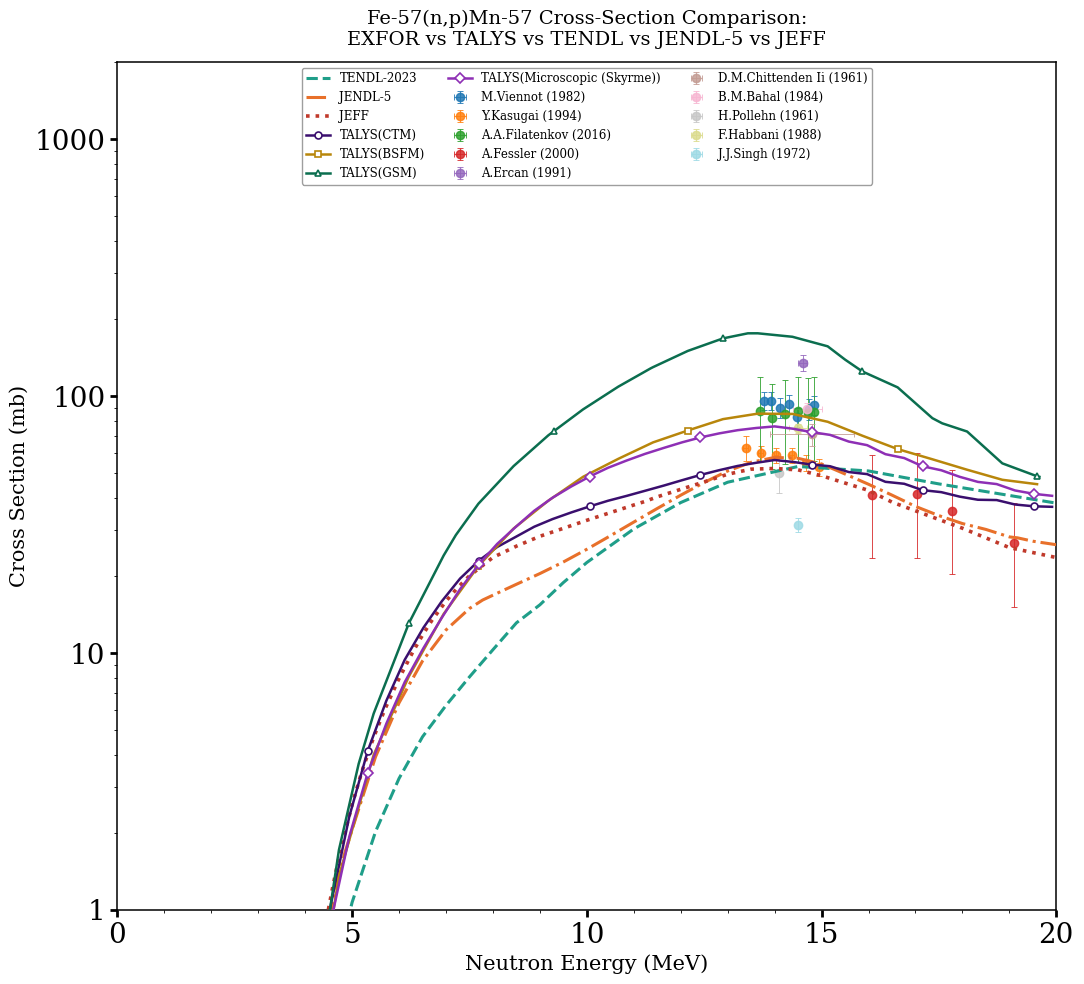

In [ ]:
import matplotlib.ticker as mticker
fig, ax = plt.subplots(figsize=(11, 10))


# ---- evaluated curves -------------------------------------------------------
CURVE_STYLE = {
    "TENDL": dict(color="#1f9e89", ls="--", lw=2.2, label="TENDL-2023"),
    "ENDF":  dict(color="#e8702a", ls="-.", lw=2.2, label="JENDL-5"),
    "JEFF":  dict(color="#c0392b", ls=":",  lw=2.6, label="JEFF"),
}
for key in ["TENDL", "ENDF", "JEFF"]:
    df = data.get(key)
    if df is not None and len(df):
        ax.plot(df["energy_MeV"], df["xs_mb"], **CURVE_STYLE[key], zorder=3)

# ---- TALYS: 4 level-density models, distinct colors + markers --------------
TALYS_STYLE = {
    "CTM":                  dict(color="#3a0f6e", marker="o", markevery=6, ls="-",  lw=1.8),
    "GSM":                  dict(color="#0b6e4f", marker="^", markevery=6, ls="-",  lw=1.8),
    "BSFM":                 dict(color="#b8860b", marker="s", markevery=6, ls="-",  lw=1.8),
    "Microscopic (Skyrme)": dict(color="#8e2fb5", marker="D", markevery=6, ls="-",  lw=1.8),
}
talys_models = data.get("TALYS")
if talys_models:
    for name, df in talys_models.items():
        if df is not None and len(df):
            style = TALYS_STYLE.get(name, dict(color="gray", marker="x", ls="-", lw=1.5))
            ax.plot(df["energy_MeV"], df["xs_mb"],
                     markersize=5, markerfacecolor="white", markeredgewidth=1.2,
                     label=f"TALYS({name})", zorder=3, **style)

# ---- EXFOR experimental points, color-coded by author/year ------------------
exfor = data.get("EXFOR")
if exfor is not None and len(exfor):
    TOP_N = 10
    counts = exfor["label"].value_counts()
    top_labels = list(counts.index[:TOP_N])
    exfor = exfor.copy()
    # keep ONLY the top-N authors; drop everything else
    exfor = exfor[exfor["label"].isin(top_labels)].copy()
    exfor["plot_label"] = exfor["label"]

    plot_labels = top_labels
    cmap = plt.cm.tab20(np.linspace(0, 1, max(len(plot_labels), 1)))

    for i, lab in enumerate(plot_labels):
        sub = exfor[exfor["plot_label"] == lab]
        ax.errorbar(
            sub["energy_MeV"], sub["xs_mb"],
            yerr=sub["dxs_mb"].where(sub["dxs_mb"] > 0, np.nan),
            xerr=sub["dE_MeV"].where(sub["dE_MeV"] > 0, np.nan),
            fmt='o',
            color=cmap[i], ecolor=cmap[i],
            markersize=6, capsize=2, elinewidth=0.7, capthick=0.7,
            linestyle="none", alpha=0.85, label=lab, zorder=2,
        )

# ---- axes scales and range --------------------------------------------------
ax.set_xscale("linear")
ax.set_yscale("log")
ax.set_xlim(0, 20)
ax.set_ylim(1, 2000)

# Set x-axis ticks
ax.set_xticks([0, 5, 10, 15, 20])
# Set y-axis ticks
ax.set_yticks([1, 10, 100, 1000])
ax.yaxis.set_major_formatter(mticker.ScalarFormatter())

# Make x and y axis marks bolder
ax.tick_params(axis='x', labelsize=20, width=2, length=5)
ax.tick_params(axis='y', labelsize=20, width=2, length=5)

ax.set_xlabel("Neutron Energy (MeV)", fontsize=15) # Increased fontsize for bolder appearance
ax.set_ylabel("Cross Section (mb)", fontsize=15) # Increased fontsize for bolder appearance
ax.set_title(
    "Fe-57(n,p)Mn-57 Cross-Section Comparison:\n"
    "EXFOR vs TALYS vs TENDL vs JENDL-5 vs JEFF",
    fontsize=14, pad=12,
)

# ---- X AXIS (linear): major ticks at 5, 10, 15, 20; minor every 1 -----------
ax.xaxis.set_major_locator(MultipleLocator(5))
ax.xaxis.set_minor_locator(MultipleLocator(1))

# ---- Y AXIS (log): major ticks at decades 10, 100, 1000; minor sub-decade ---
ax.yaxis.set_major_locator(LogLocator(base=10))
ax.yaxis.set_minor_locator(LogLocator(base=10, subs=np.arange(2, 10) * 0.1))
ax.yaxis.set_minor_formatter(NullFormatter())

# Removed grid lines
# ax.grid(which="major", ls="-",  lw=0.6, alpha=0.5)
# ax.grid(which="minor", ls=":",  lw=0.4, alpha=0.3)

ax.legend(loc="upper center", ncol=3, fontsize=8.5,
          framealpha=0.95, edgecolor="0.6")

fig.tight_layout()

OUT_PNG = "Fe57_np_combined_comparison_plot.png"
fig.savefig(OUT_PNG, dpi=600, bbox_inches="tight")

print(f"Saved plot -> {OUT_PNG}")

In [ ]:
plt.show()
